# Client segmentation by target rate: SOM and alternative clustering methods

This notebook starts from a **per-`obs_id` dataframe**: one row per observation/client record, with predictor features and a binary target. It compares:

- **SOM**: tune map size and training settings, then cluster the SOM codebook vectors.
- **K-means**: tune the number of clusters and initialisation stability.
- **Gaussian mixture models (GMM)**: tune component count and covariance structure.
- **Agglomerative clustering**: tune cluster count and linkage.

The target is excluded from the feature matrix. Clusters are formed from client characteristics; target rates are calculated afterwards to assess whether the resulting groups differ in outcome incidence. This keeps the clustering unsupervised rather than directly optimising clusters against the target.

The notebook uses internal clustering metrics for parameter selection (primarily silhouette, with Davies–Bouldin and Calinski–Harabasz as supporting diagnostics), then reports target rates, confidence intervals, and feature profiles. Do not interpret a higher target rate as causal.

**Input contract:** a dataframe with one row per `obs_id`, a binary target column, and numeric/categorical predictor columns. If multiple rows exist per `obs_id`, aggregate them before using this notebook.

Note the bottom section shows feature differences per cluster per model

## 1. Configuration and imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)
from sklearn.decomposition import PCA
from sklearn.model_selection import ParameterGrid

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Update these values to match your dataframe ----
DATA_PATH = Path("working_data/")
TARGET = "target_value"
OBS_ID = "obs_id"
CUSTOMER_ID = "cifwithcheckdigit"  # set to None if unavailable

# Columns that must never enter the clustering feature matrix.
EXCLUDE_COLUMNS = {
    OBS_ID, CUSTOMER_ID, TARGET,
    "target_rule", "total_paid", "payment_count",
    "m0_monthenddate", "transactiondate",
}

RANDOM_STATE = 0
MAX_SILHOUETTE_ROWS = 8000  # silhouette is sampled above this size
BOOTSTRAP_REPEATS = 500
MIN_CLUSTER_SIZE = 0.01     # reject solutions with clusters below 1% of rows
MAX_FEATURES_FOR_PLOTS = 20
OUT_DIR = Path("client_cluster_analysis")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# If you already have the dataframe in memory, replace the loading cell below
# with: df = your_dataframe.copy()

RULE_TO_TARGET = {2: 0, 3: 0, 4: 1, 5: 1, 6: 0, 7: 1, 8: 1}
RULE_NAMES = {2: "2 last balance < 250", 3: "3 payments due < 50", 4: "4 received <= 0",
              5: "5 received < due", 6: "6 received >= due", 7: "7 arrears up at window end",
              8: "8 arrears up at last txn"}


## 2. Load and validate the per-`obs_id` dataframe

In [4]:
from build_dataset import load_dataset, impute_train_only
D = load_dataset("dataset")
lab = D["labels"]
target_rule = lab["target_rule"]
X, y, groups, tr, te = D["X_all"], D["y"], D["groups"], D["train"], D["test"]     # same shapes as select_features expects
Xi = impute_train_only(X, tr)   

In [5]:
target_rule

obs_id
O0000000    4
O0000001    6
O0000002    5
O0000003    6
O0000004    4
           ..
O0041948    6
O0041949    4
O0041950    6
O0041951    6
O0041952    6
Name: target_rule, Length: 41953, dtype: int64

## 3. Prepare predictors

Numeric variables are median-imputed and standardised. Categorical variables are mode-imputed and one-hot encoded. Constant and all-missing columns are removed. The target, identifiers, dates, and known outcome-derived fields are excluded.

For very wide data, one-hot encoding can increase dimensionality. The notebook reports the resulting size so this can be reviewed before fitting.

In [6]:
excluded = set(EXCLUDE_COLUMNS)
if CUSTOMER_ID is not None:
    excluded.add(CUSTOMER_ID)

feature_cols = [c for c in Xi.columns if c not in excluded]
X_raw = Xi.copy()
obs_ids = Xi.copy().reset_index()[OBS_ID]

# Convert booleans to numeric; remove columns with no usable variation.
for c in X_raw.select_dtypes(include=["bool"]).columns:
    X_raw[c] = X_raw[c].astype("int8")

numeric_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in X_raw.columns if c not in numeric_cols]

numeric_cols = [
    c for c in numeric_cols
    if X_raw[c].notna().any() and X_raw[c].nunique(dropna=True) > 1
]
categorical_cols = [
    c for c in categorical_cols
    if X_raw[c].notna().any() and X_raw[c].nunique(dropna=True) > 1
]
X_raw = X_raw[numeric_cols + categorical_cols]

transformers = []
if numeric_cols:
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    transformers.append(("numeric", numeric_pipe, numeric_cols))
if categorical_cols:
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    transformers.append(("categorical", categorical_pipe, categorical_cols))

if not transformers:
    raise ValueError("No usable predictor columns remain after exclusions.")

preprocessor = ColumnTransformer(transformers, remainder="drop")
X = preprocessor.fit_transform(X_raw)
X = np.asarray(X, dtype=np.float32)

if not np.isfinite(X).all():
    raise ValueError("Preprocessed feature matrix contains non-finite values.")

feature_names = preprocessor.get_feature_names_out()
print("Raw predictors:", X_raw.shape[1])
print("Encoded predictors:", X.shape[1])
print("Matrix shape:", X.shape)


Raw predictors: 193
Encoded predictors: 193
Matrix shape: (41953, 193)


## 4. Shared evaluation functions

Silhouette is the primary tuning criterion. Davies–Bouldin is better when lower; Calinski–Harabasz is better when higher. Scores are computed on a consistent random sample when the dataset is large.

A candidate is rejected if it produces fewer than two clusters, one cluster, or a very small cluster. The minimum-size threshold is configurable above.

In [7]:
def evaluate_labels(Z, labels, max_rows=MAX_SILHOUETTE_ROWS, seed=RANDOM_STATE):
    labels = np.asarray(labels)
    unique, counts = np.unique(labels, return_counts=True)
    n_clusters = len(unique)
    if n_clusters < 2 or n_clusters >= len(labels):
        return None
    #if counts.min() / len(labels) < MIN_CLUSTER_SIZE:
    #    print("Not counted due to cluster size")
    #    return None

    if len(Z) > max_rows:
        rng = np.random.default_rng(seed)
        idx = rng.choice(len(Z), size=max_rows, replace=False)
        Z_eval = Z[idx]
        labels_eval = labels[idx]
        if len(np.unique(labels_eval)) < 2:
            return None
    else:
        Z_eval, labels_eval = Z, labels

    return {
        "n_clusters": n_clusters,
        "silhouette": silhouette_score(Z_eval, labels_eval),
        "davies_bouldin": davies_bouldin_score(Z_eval, labels_eval),
        "calinski_harabasz": calinski_harabasz_score(Z_eval, labels_eval),
        "min_cluster_share": counts.min() / len(labels),
    }


def make_result_row(method, params, scores):
    return {"method": method, **params, **scores}


def cluster_rate_table(labels, target, ids=None):
    tmp = pd.DataFrame({
        "cluster": np.asarray(labels),
        "target": np.asarray(target),
    }, index=ids)
    out = tmp.groupby("cluster").agg(
        n=("target", "size"),
        positives=("target", "sum"),
        target_rate=("target", "mean"),
    )
    out["share"] = out["n"] / len(tmp)
    out["rate_minus_overall"] = out["target_rate"] - tmp["target"].mean()
    return out.sort_values("target_rate", ascending=False)


def bootstrap_rate_intervals(labels, target, repeats=BOOTSTRAP_REPEATS, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    tmp = pd.DataFrame({"cluster": np.asarray(labels), "target": np.asarray(target)})
    rows = []
    for cluster_id, part in tmp.groupby("cluster"):
        vals = part["target"].to_numpy()
        boot = np.array([
            rng.choice(vals, size=len(vals), replace=True).mean()
            for _ in range(repeats)
        ])
        rows.append({
            "cluster": cluster_id,
            "rate": vals.mean(),
            "ci_lower": np.quantile(boot, 0.025),
            "ci_upper": np.quantile(boot, 0.975),
        })
    return pd.DataFrame(rows).set_index("cluster")


## 5. K-means: tune the number of clusters and initialisation

In [8]:
# Candidate k values adapt to the number of observations.
n = len(X)
k_max = min(15, max(5, int(np.sqrt(n / 2))))
k_values = range(5, k_max + 1)

kmeans_rows = []
kmeans_models = {}
for k in k_values:

    model = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=RANDOM_STATE,
        algorithm="lloyd",
    )
    labels = model.fit_predict(X)
    scores = evaluate_labels(X, labels)

    if scores is not None:
        params = {"k": k, "n_init": 20}
        kmeans_rows.append(make_result_row("kmeans", params, scores))
        kmeans_models[k] = (model, labels)

kmeans_results = pd.DataFrame(kmeans_rows).sort_values(
    ["silhouette", "davies_bouldin"], ascending=[False, True]
)
display(kmeans_results)
if kmeans_results.empty:
    raise RuntimeError("No valid K-means solution. Review feature scaling or MIN_CLUSTER_SIZE.")


,method,k,n_init,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
0,kmeans,5,20,5,0.093521,2.380168,525.549451,0.005435
1,kmeans,6,20,6,0.066593,2.589932,475.727196,0.003456
2,kmeans,7,20,7,0.066362,2.271574,478.675808,0.000048
3,kmeans,8,20,8,0.060248,2.432518,438.010906,0.000048
5,kmeans,10,20,10,0.053943,2.708388,362.113533,0.000024
4,kmeans,9,20,9,0.048630,2.825573,388.744737,0.000024
7,kmeans,12,20,12,0.045968,2.457799,337.352297,0.000048
8,kmeans,13,20,13,0.042465,2.590842,319.865496,0.000048
6,kmeans,11,20,11,0.041373,2.830063,336.353639,0.000024
9,kmeans,14,20,14,0.040030,2.816655,322.515839,0.000024


## 6. Gaussian mixture models: tune components and covariance structure

GMMs provide soft membership probabilities as well as hard cluster assignments. BIC is used as the model-selection criterion within the GMM family; silhouette and cluster-size checks are also reported for comparability.

In [9]:
gmm_rows = []
gmm_models = {}
GMM_TUNING_MAX_ROWS = 15000
if n > GMM_TUNING_MAX_ROWS:
    rng = np.random.default_rng(RANDOM_STATE)
    gmm_idx = np.sort(rng.choice(n, GMM_TUNING_MAX_ROWS, replace=False))
else:
    gmm_idx = np.arange(n)
X_gmm = X[gmm_idx]
component_values = range(2, min(10, max(3, int(np.sqrt(len(X_gmm) / 2)))) + 1)
covariance_types = ["full", "tied", "diag", "spherical"]

for covariance_type in covariance_types:
    for components in component_values:
        try:
            model = GaussianMixture(
                n_components=components,
                covariance_type=covariance_type,
                n_init=3,
                reg_covar=1e-5,
                random_state=RANDOM_STATE,
            )
            labels = model.fit_predict(X_gmm)
            scores = evaluate_labels(X_gmm, labels)
            if scores is None:
                continue
            params = {
                "components": components,
                "covariance_type": covariance_type,
                "bic": model.bic(X_gmm),
                "aic": model.aic(X_gmm),
            }
            gmm_rows.append(make_result_row("gmm", params, scores))
            gmm_models[(components, covariance_type)] = (model, labels)
        except (ValueError, np.linalg.LinAlgError):
            continue

gmm_results = pd.DataFrame(gmm_rows)
if not gmm_results.empty:
    display(gmm_results.sort_values(["bic", "silhouette"], ascending=[True, False]))
else:
    print("No valid GMM candidate. This can happen with high-dimensional or highly collinear data.")


,method,components,covariance_type,bic,aic,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
2,gmm,4,diag,4.309483e+06,4.297701e+06,4,0.038731,4.087921,472.453724,0.069600
1,gmm,3,diag,4.999787e+06,4.990953e+06,3,0.085315,3.713433,578.535813,0.145467
0,gmm,2,diag,6.220736e+06,6.214849e+06,2,0.102901,2.778501,872.462060,0.448200
11,gmm,10,spherical,6.600154e+06,6.585311e+06,10,0.004283,3.893818,277.477734,0.006400
10,gmm,9,spherical,6.641090e+06,6.627731e+06,9,0.009859,3.868289,301.348268,0.006733
9,gmm,8,spherical,6.707777e+06,6.695904e+06,8,0.044463,3.515429,328.595937,0.007267
8,gmm,7,spherical,6.772653e+06,6.762265e+06,7,0.008897,4.021905,333.210302,0.008200
7,gmm,6,spherical,6.832979e+06,6.824076e+06,6,0.028521,4.104938,372.088303,0.008200
6,gmm,5,spherical,6.935328e+06,6.927910e+06,5,0.043826,4.234189,410.760792,0.009867
5,gmm,4,spherical,7.061508e+06,7.055575e+06,4,0.059201,3.675380,506.590967,0.026600


## 7. Agglomerative clustering: tune cluster count and linkage

Ward linkage is evaluated with Euclidean distance. Average and complete linkage are also tested with Euclidean distance. For large datasets, hierarchical clustering can be expensive; the optional cap below allows a reproducible tuning sample. If sampling is used, the final model is refitted on the full dataset only if computationally feasible.

In [12]:
AGGLOMERATIVE_MAX_ROWS = 12000
if n > AGGLOMERATIVE_MAX_ROWS:
    rng = np.random.default_rng(RANDOM_STATE)
    agg_idx = np.sort(rng.choice(n, AGGLOMERATIVE_MAX_ROWS, replace=False))
else:
    agg_idx = np.arange(n)

X_agg = X[agg_idx]
agg_rows = []
agg_models = {}
agg_k_max = min(15, max(5, int(np.sqrt(len(X_agg) / 2))))

for linkage in ["ward", "average", "complete"]:
    for k in range(5, agg_k_max + 1):
        try:
            model = AgglomerativeClustering(n_clusters=k, linkage=linkage)
            labels = model.fit_predict(X_agg)
            scores = evaluate_labels(X_agg, labels)
            if scores is None:
                continue
            params = {"k": k, "linkage": linkage, "tuning_n": len(X_agg)}
            agg_rows.append(make_result_row("agglomerative", params, scores))
            agg_models[(k, linkage)] = (model, labels)
        except (ValueError, MemoryError):
            continue

agg_results = pd.DataFrame(agg_rows)
if not agg_results.empty:
    display(agg_results.sort_values(
        ["silhouette", "davies_bouldin"], ascending=[False, True]
    ))
else:
    print("No valid agglomerative candidate.")


,method,k,linkage,tuning_n,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
11,agglomerative,5,average,12000,5,0.903467,0.055093,532.597161,0.000083
22,agglomerative,5,complete,12000,5,0.903467,0.055093,532.597161,0.000083
12,agglomerative,6,average,12000,6,0.844360,0.078888,382.117734,0.000083
23,agglomerative,6,complete,12000,6,0.844360,0.078888,382.117734,0.000083
13,agglomerative,7,average,12000,7,0.830935,0.088536,304.057590,0.000083
14,agglomerative,8,average,12000,8,0.826804,0.094288,256.785092,0.000083
15,agglomerative,9,average,12000,9,0.787227,0.492017,234.965745,0.000083
16,agglomerative,10,average,12000,10,0.786271,0.585518,212.476984,0.000083
17,agglomerative,11,average,12000,11,0.784053,0.470872,189.814621,0.000083
18,agglomerative,12,average,12000,12,0.779095,0.459464,173.552324,0.000083


## 8. SOM: tune map size and training settings

The SOM is trained on the same preprocessed feature matrix. Map dimensions are generated from dataset size rather than fixed in advance. A small candidate set of map sizes, neighbourhood radii, learning rates, and training lengths is evaluated.

For each SOM candidate:
1. Quantisation error measures how closely observations match their best-matching units (BMUs).
2. Topographic error measures how often the first and second BMUs are not adjacent.
3. The codebook vectors are clustered with K-means; the resulting observation labels are evaluated using silhouette.

Install `MiniSom` if it is not already available.

In [13]:
%pip -q install MiniSom


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: /Users/hoyle/Documents/Uni/4th_Year/MOR441-CAP/MOR-assignment3/.venv/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from minisom import MiniSom

# Map-size candidates scale with n. Keep the grid compact enough to avoid
# creating many nearly empty neurons.
base_side = max(3, int(round(np.sqrt(np.sqrt(n)))))
map_sides = sorted(set([
    max(3, base_side - 2),
    base_side,
    min(20, base_side + 2),
]))
som_map_shapes = [(side, side) for side in map_sides[:2]]

# Parameter candidates are deliberately varied; the best combination is selected
# using quantisation/topographic error and downstream codebook-cluster silhouette.
som_sigmas = [max(0.8, side / 4) for side in map_sides]
som_learning_rates = [0.2, 0.5]
som_epochs = [20, 50]
som_cluster_counts = sorted(set([4, 5, 6, 8, 10]))
som_cluster_counts = [k for k in som_cluster_counts if k < n]

# Use a deterministic subset for SOM hyperparameter search if n is very large.
SOM_TUNING_MAX_ROWS = 12000
if n > SOM_TUNING_MAX_ROWS:
    rng = np.random.default_rng(RANDOM_STATE)
    som_idx = np.sort(rng.choice(n, SOM_TUNING_MAX_ROWS, replace=False))
else:
    som_idx = np.arange(n)
X_som_tune = X[som_idx]

som_rows = []
som_candidates = {}
for rows, cols in som_map_shapes:
    for sigma in sorted(set([max(0.8, min(rows, cols) / 4), max(1.0, min(rows, cols) / 2)])):
        for learning_rate in som_learning_rates:
            for epochs in som_epochs:
                som = MiniSom(
                    x=rows, y=cols, input_len=X.shape[1],
                    sigma=sigma, learning_rate=learning_rate,
                    neighborhood_function="gaussian",
                    random_seed=RANDOM_STATE,
                )
                som.random_weights_init(X_som_tune)
                som.train_random(X_som_tune, num_iteration=epochs * len(X_som_tune))

                bmu = np.array([som.winner(row) for row in X_som_tune])
                bmu_flat = bmu[:, 0] * cols + bmu[:, 1]
                qe = som.quantization_error(X_som_tune)
                te = som.topographic_error(X_som_tune)

                codebook = som.get_weights().reshape(rows * cols, X.shape[1])
                # Exclude unused neurons when assigning codebook clusters.
                occupied = np.unique(bmu_flat)
                occupied_vectors = codebook[occupied]

                for k in som_cluster_counts:
                    if k >= len(occupied):
                        continue
                    km_codebook = KMeans(
                        n_clusters=k, n_init=10, random_state=RANDOM_STATE
                    )
                    neuron_labels = km_codebook.fit_predict(occupied_vectors)
                    neuron_to_cluster = dict(zip(occupied, neuron_labels))
                    obs_labels = np.array([neuron_to_cluster[u] for u in bmu_flat])
                    scores = evaluate_labels(X_som_tune, obs_labels)
                    if scores is None:
                        continue

                    params = {
                        "rows": rows, "cols": cols, "sigma": sigma,
                        "learning_rate": learning_rate, "epochs": epochs,
                        "cluster_k": k, "quantization_error": qe,
                        "topographic_error": te,
                    }
                    som_rows.append(make_result_row("som", params, scores))
                    som_candidates[(rows, cols, sigma, learning_rate, epochs, k)] = {
                        "som": som, "km_codebook": km_codebook,
                        "occupied": occupied, "neuron_labels": neuron_labels,
                        "tuning_labels": obs_labels,
                    }

som_results = pd.DataFrame(som_rows)
if som_results.empty:
    print("No valid SOM candidate. Consider reducing MIN_CLUSTER_SIZE or expanding the candidate ranges.")
else:
    display(som_results.sort_values(
        ["silhouette", "quantization_error", "topographic_error"],
        ascending=[False, True, True]
    ).head(20))

,method,rows,cols,sigma,learning_rate,epochs,cluster_k,quantization_error,topographic_error,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
21,som,12,12,3.0,0.5,50,4,10.015735,0.115083,4,0.110586,2.377201,421.820143,0.000917
49,som,12,12,6.0,0.5,50,4,10.736441,0.042000,4,0.105450,2.408902,427.084870,0.000833
14,som,12,12,3.0,0.5,20,4,9.995775,0.096917,4,0.103282,2.275786,400.996655,0.001250
42,som,12,12,6.0,0.5,20,4,10.671501,0.038833,4,0.096045,2.477442,453.445744,0.000917
15,som,12,12,3.0,0.5,20,5,9.995775,0.096917,5,0.093442,2.333392,425.637394,0.000583
35,som,12,12,6.0,0.2,50,4,10.571175,0.030083,4,0.082127,2.971849,440.002680,0.008583
57,som,14,14,3.5,0.2,20,5,9.802113,0.052083,5,0.079914,2.547840,463.309712,0.016417
71,som,14,14,3.5,0.5,20,5,9.920534,0.085583,5,0.078497,2.556058,454.382841,0.011583
56,som,14,14,3.5,0.2,20,4,9.802113,0.052083,4,0.076958,2.691698,529.359711,0.016417
1,som,12,12,3.0,0.2,20,5,9.875207,0.071000,5,0.076184,2.566697,459.318105,0.006500


## 9. Compare candidate methods and select representative solutions

The top candidate from each family is retained for comparison. Silhouette is the primary ranking metric; the other internal metrics and SOM errors are retained to make trade-offs visible. A single metric should not be treated as proof that a clustering is meaningful.

In [37]:
def gini_scores(labels, y):
    """Gini impurity of the target inside the clusters (lower = purer) and the gain over no clustering."""
    labels, y = np.asarray(labels), np.asarray(y)
    ct = pd.crosstab(labels, y).to_numpy().astype(float)            # clusters x target classes
    n = ct.sum()
    size = ct.sum(1) / n
    p = ct / ct.sum(1, keepdims=True)
    weighted = float((size * (1 - (p ** 2).sum(1))).sum())           # size-weighted Gini impurity
    base = 1 - ((ct.sum(0) / n) ** 2).sum()                          # impurity with a single cluster
    return {"gini_impurity": weighted,
            "gini_gain": base - weighted,                            # higher = clusters separate the target better
            "gini_gain_rel": (base - weighted) / base if base > 0 else np.nan}

# CHANGED Y TO TARGET_RULE
y_arr = np.asarray(target_rule)

def som_labels_for(key):
    rows_, cols_ = key[0], key[1]
    c = som_candidates[key]
    som_, occ, nl = c["som"], c["occupied"], c["neuron_labels"]
    w = som_.get_weights().reshape(rows_ * cols_, X.shape[1])
    n2c = dict(zip(occ, nl))
    bmu = np.array([som_.winner(r) for r in X])
    flat = bmu[:, 0] * cols_ + bmu[:, 1]
    for u in np.unique(flat):
        if u not in n2c:
            n2c[u] = nl[np.argmin(np.linalg.norm(w[occ] - w[u], axis=1))]
    return np.array([n2c[u] for u in flat])

# add the Gini columns to each results table
if kmeans_results is not None and not kmeans_results.empty:
    g = [gini_scores(kmeans_models[int(r.k)][1], y_arr) for r in kmeans_results.itertuples()]
    kmeans_results = pd.concat([kmeans_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)

if gmm_results is not None and not gmm_results.empty:
    g = [gini_scores(gmm_models[(int(r.components), r.covariance_type)][0].predict(X), y_arr)
         for r in gmm_results.itertuples()]
    gmm_results = pd.concat([gmm_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)
"""
if agg_results is not None and not agg_results.empty:      # tuned on a sample: score against the sample's target
    g = [gini_scores(agg_models[(int(r.k), r.linkage)][1], y_arr[agg_idx]) for r in agg_results.itertuples()]
    agg_results = pd.concat([agg_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)
"""

if som_results is not None and not som_results.empty:      # slowest part: one pass over X per SOM candidate
    keys = [(int(r.rows), int(r.cols), float(r.sigma), float(r.learning_rate), int(r.epochs), int(r.cluster_k))
            for r in som_results.itertuples()]
    g = [gini_scores(som_labels_for(k), y_arr) for k in keys]
    som_results = pd.concat([som_results.reset_index(drop=True), pd.DataFrame(g)], axis=1)

In [40]:
candidate_tables = []
for name, table in [("kmeans", kmeans_results), ("gmm", gmm_results), ("som", som_results)]:
    if table is not None and not table.empty:
        table = table.loc[:, ~table.columns.duplicated(keep="last")].reset_index(drop=True)
        if "method" in table.columns:
            table = table.rename(columns={"method": "method_detail"})   # keep the original column, under another name
        table.insert(0, "method", name)
        candidate_tables.append(table)

In [42]:
K_MIN, K_MAX = 2, 7
TOP_N = 3

candidate_tables = []
for name, table in [("kmeans", kmeans_results), ("gmm", gmm_results), ("som", som_results)]:
    if table is not None and not table.empty:
        table = table.loc[:, ~table.columns.duplicated(keep="last")].reset_index(drop=True)
        if "method" in table.columns:
            table = table.rename(columns={"method": "method_detail"})   # keep the original column, under another name
        table.insert(0, "method", name)
        candidate_tables.append(table)

def limit_k(table, col):
    if table is None or table.empty:
        return table
    t = table.copy()
    t["n_clusters"] = t[col]
    return t[t["n_clusters"].between(K_MIN, K_MAX)].reset_index(drop=True)

def top_n(table, n=TOP_N, by=("gini_gain", "silhouette")):
    """Keep the n best rows of one model's results table (best first)."""
    if table is None or table.empty:
        return table
    t = table.loc[:, ~table.columns.duplicated(keep="last")]
    return t.sort_values(list(by), ascending=[False] * len(by)).head(n).reset_index(drop=True)

kmeans_results = top_n(limit_k(kmeans_results, "k"))
gmm_results    = top_n(limit_k(gmm_results, "components"))
som_results    = top_n(limit_k(som_results, "cluster_k"))
# agg_results = top_n(limit_k(agg_results, "k"))

candidate_tables = []
for name, table in [("kmeans", kmeans_results), ("gmm", gmm_results), ("som", som_results)]:
    if table is not None and not table.empty:
        table = table.loc[:, ~table.columns.duplicated(keep="last")].reset_index(drop=True)
        if "method" in table.columns:
            table = table.rename(columns={"method": "method_detail"})   # keep the original column, under another name
        table.insert(0, "method", name)
        candidate_tables.append(table)

all_results = pd.concat(candidate_tables, ignore_index=True, sort=False)

display(all_results.sort_values(
    ["method", "gini_gain", "silhouette"], ascending=[True, False, False]
))

best_by_method = {}
if not kmeans_results.empty:
    r = kmeans_results.sort_values("silhouette", ascending=False).iloc[0]
    best_by_method["kmeans"] = kmeans_models[int(r["k"])][1]

if not gmm_results.empty:
    r = gmm_results.sort_values(["bic", "silhouette"], ascending=[True, False]).iloc[0]
    key = (int(r["components"]), r["covariance_type"])
    best_by_method["gmm"] = gmm_models[key][0].predict(X)
"""
if not agg_results.empty:
    r = agg_results.sort_values("silhouette", ascending=False).iloc[0]
    key = (int(r["k"]), r["linkage"])
    # If tuned on a sample, only sample labels are available here.
    best_by_method["agglomerative_sample"] = (agg_idx, agg_models[key][1])
"""

if not som_results.empty:
    r = som_results.sort_values(
        ["silhouette", "quantization_error", "topographic_error"],
        ascending=[False, True, True]
    ).iloc[0]
    key = (
        int(r["rows"]), int(r["cols"]), float(r["sigma"]),
        float(r["learning_rate"]), int(r["epochs"]), int(r["cluster_k"])
    )
    chosen = som_candidates[key]
    chosen_som = chosen["som"]
    chosen_rows, chosen_cols = key[0], key[1]
    occupied = chosen["occupied"]
    neuron_labels = chosen["neuron_labels"]
    neuron_to_cluster = dict(zip(occupied, neuron_labels))
    full_bmu = np.array([chosen_som.winner(row) for row in X])
    full_bmu_flat = full_bmu[:, 0] * chosen_cols + full_bmu[:, 1]
    # A neuron not occupied during tuning is assigned to its nearest occupied
    # codebook vector, so every observation receives a cluster.
    occupied_vectors = chosen_som.get_weights().reshape(
        chosen_rows * chosen_cols, X.shape[1]
    )[occupied]
    all_weights = chosen_som.get_weights().reshape(
        chosen_rows * chosen_cols, X.shape[1]
    )
    for neuron_id in np.unique(full_bmu_flat):
        if neuron_id not in neuron_to_cluster:
            nearest = np.argmin(
                np.linalg.norm(occupied_vectors - all_weights[neuron_id], axis=1)
            )
            neuron_to_cluster[neuron_id] = neuron_labels[nearest]
    best_by_method["som"] = np.array(
        [neuron_to_cluster[u] for u in full_bmu_flat]
    )

print("Selected:", list(best_by_method))


,method,method_detail,k,n_init,n_clusters,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,gini_impurity,...,bic,aic,rows,cols,sigma,learning_rate,epochs,cluster_k,quantization_error,topographic_error
3,gmm,gmm,NaN,NaN,7,0.008897,4.021905,333.210302,0.008200,0.611077,...,6.772653e+06,6.762265e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,gmm,gmm,NaN,NaN,6,0.028521,4.104938,372.088303,0.008200,0.612211,...,6.832979e+06,6.824076e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,gmm,gmm,NaN,NaN,5,0.043826,4.234189,410.760792,0.009867,0.618145,...,6.935328e+06,6.927910e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,kmeans,kmeans,7.0,20.0,7,0.066362,2.271574,478.675808,0.000048,0.612222,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,kmeans,kmeans,6.0,20.0,6,0.066593,2.589932,475.727196,0.003456,0.613540,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,kmeans,kmeans,5.0,20.0,5,0.093521,2.380168,525.549451,0.005435,0.614714,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,som,som,NaN,NaN,6,0.029552,3.171943,378.656599,0.047917,0.600040,...,NaN,NaN,14.0,14.0,7.0,0.2,50.0,6.0,10.374471,0.012333
7,som,som,NaN,NaN,6,0.026857,3.113915,371.299754,0.050750,0.601160,...,NaN,NaN,14.0,14.0,3.5,0.5,50.0,6.0,9.921211,0.075167
8,som,som,NaN,NaN,4,0.037152,3.521146,473.933171,0.182083,0.601912,...,NaN,NaN,14.0,14.0,7.0,0.2,50.0,4.0,10.374471,0.012333


Selected: ['kmeans', 'gmm', 'som']


## 10. Compare target rules for selected clusterings

Target rates are calculated only after clustering. The table includes cluster size and the difference from the overall target prevalence. Bootstrap intervals provide a rough measure of uncertainty; they do not account for model-selection uncertainty.

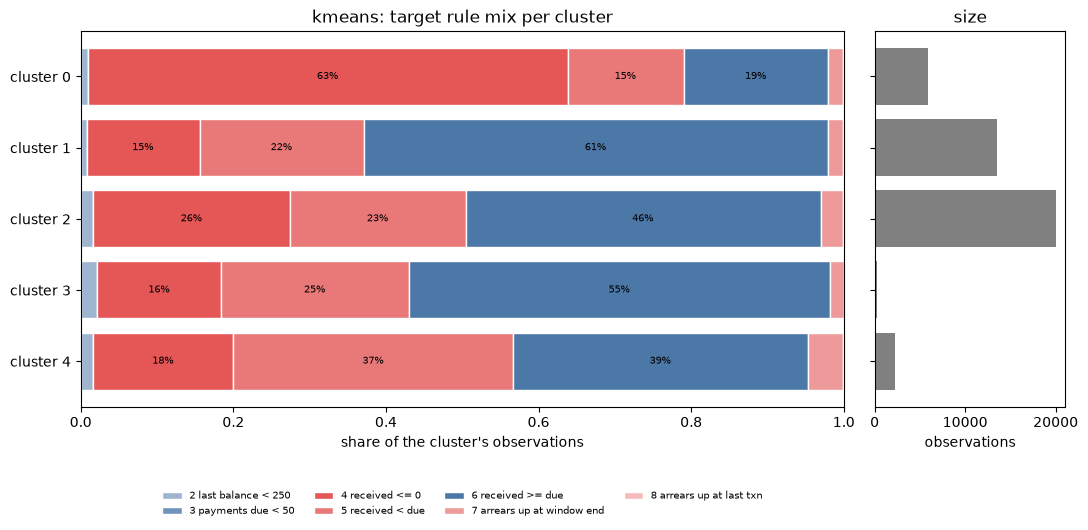

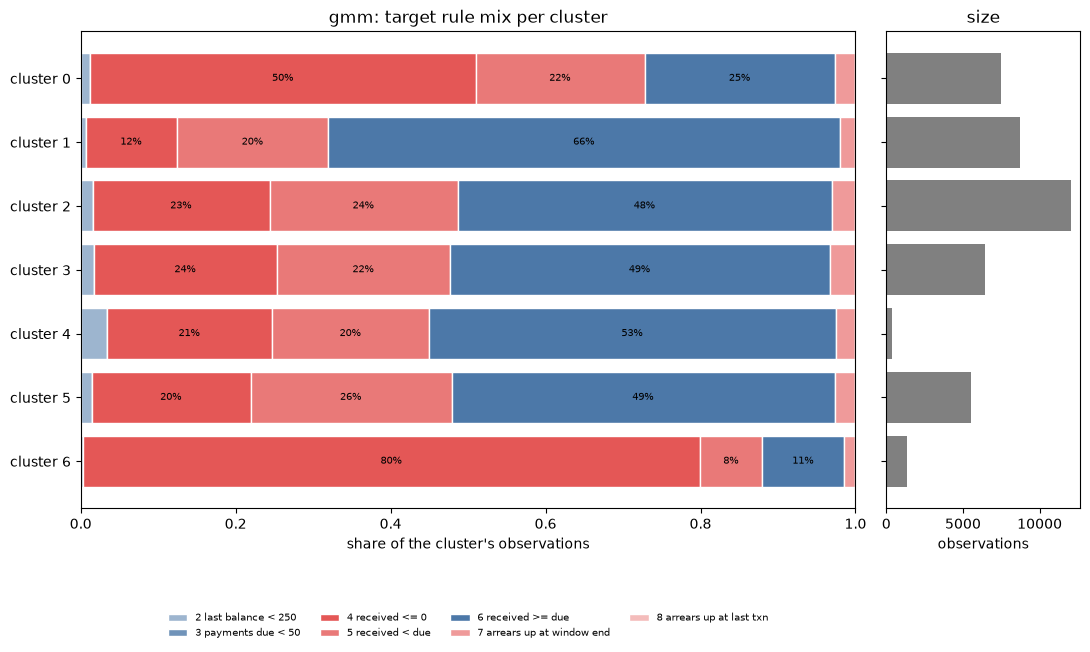

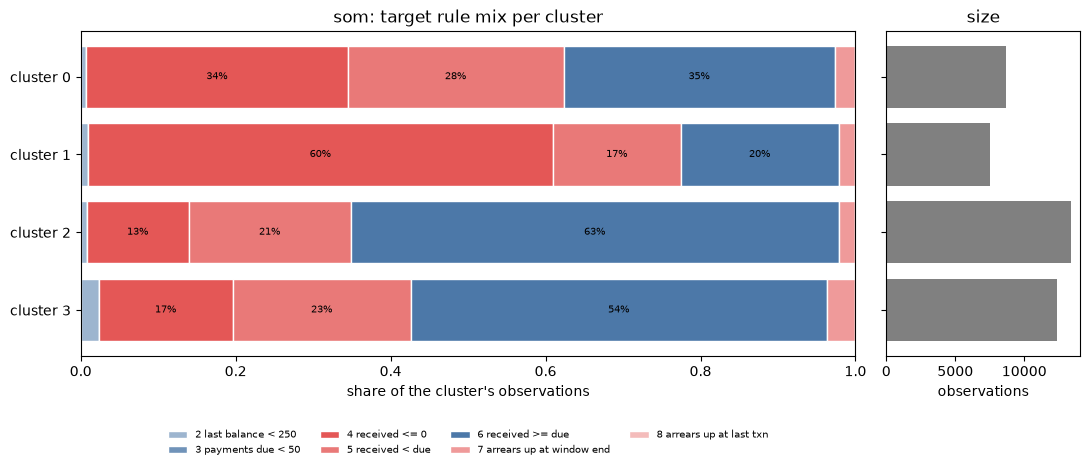

In [47]:
import matplotlib.colors as mc

# rule for every row of X, same order as X (numbers 2-8). Use your own variable here.
# e.g. rule_arr = lab["target_rule"].to_numpy()   or   rule.loc[X.index].to_numpy()
rule_arr = y_arr

RULE_TO_TARGET = {2: 0, 3: 0, 4: 1, 5: 1, 6: 0, 7: 1, 8: 1}
RULE_NAMES = {2: "2 last balance < 250", 3: "3 payments due < 50", 4: "4 received <= 0", 5: "5 received < due",
              6: "6 received >= due", 7: "7 arrears up at window end", 8: "8 arrears up at last txn"}
rules = sorted(RULE_TO_TARGET)

# blues = target 0, reds = target 1 (so the bar also shows the binary mix at a glance)
shade = {2: .55, 3: .8, 6: 1.0, 4: 1.0, 5: .8, 7: .6, 8: .4}
def tint(c, a): return tuple(a * np.array(mc.to_rgb(c)) + (1 - a) * np.ones(3))
colors = {r: tint("#4c78a8" if RULE_TO_TARGET[r] == 0 else "#e45756", shade[r]) for r in rules}

rule_mix = {}
for method, labels in profile_methods.items():
    df = pd.DataFrame({"cluster": np.asarray(labels), "rule": rule_arr}).dropna()
    df["rule"] = df["rule"].astype(int)
    ct = pd.crosstab(df["cluster"], df["rule"]).reindex(columns=rules, fill_value=0)
    share = ct.div(ct.sum(axis=1), axis=0)
    size = ct.sum(axis=1)
    rule_mix[method] = share

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 0.6 * len(ct) + 2.5), sharey=True,
                                  gridspec_kw={"width_ratios": [4, 1]})
    left = np.zeros(len(ct))
    for r in rules:
        ax.barh(range(len(ct)), share[r], left=left, color=colors[r], edgecolor="white", label=RULE_NAMES[r])
        for i, v in enumerate(share[r]):
            if v >= 0.06:
                ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=7)
        left += share[r].to_numpy()
    ax.set_yticks(range(len(ct))); ax.set_yticklabels([f"cluster {c}" for c in ct.index]); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.set_xlabel("share of the cluster's observations")
    ax.set_title(f"{method}: target rule mix per cluster")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=7, frameon=False)
    ax2.barh(range(len(ct)), size, color="grey"); ax2.set_xlabel("observations"); ax2.set_title("size")
    fig.tight_layout()
    plt.show()

# the numbers behind the bars
# pd.concat(rule_mix, names=["method", "cluster"]).round(3).to_csv("cluster_rule_mix.csv")


## 11. Feature profiles and distinguishing characteristics

For each full-data solution, compare cluster means/medians with the overall population. Standardised differences are descriptive. For categorical variables, use encoded feature proportions; for readability, display the strongest features only.

In [45]:
def feature_profile(Z_frame, labels):
    frame = pd.DataFrame(Z_frame, columns=feature_names)
    frame["cluster"] = np.asarray(labels)
    return frame.groupby("cluster").mean()

profile_methods = {
    name: labels for name, labels in best_by_method.items()
    if name != "agglomerative_sample" and len(labels) == len(X)
}

for method, labels in profile_methods.items():
    prof = feature_profile(X, labels)
    overall = pd.Series(X.mean(axis=0), index=feature_names)
    sd = pd.Series(X.std(axis=0), index=feature_names).replace(0, np.nan)
    differences = (prof - overall) / sd
    print(f"\n{method}: strongest cluster-feature differences")
    for cluster_id in differences.index:
        top = differences.loc[cluster_id].abs().sort_values(ascending=False).head(MAX_FEATURES_FOR_PLOTS).index
        display(differences.loc[[cluster_id], top].T.rename(columns={cluster_id: f"cluster_{cluster_id}"}))


kmeans: strongest cluster-feature differences


cluster,cluster_0
numeric__run_essentials_slog,-1.831835
numeric__run_spend_slog,-1.808114
numeric__run_outflow_slog,-1.797427
numeric__grp_bank_fees_interest_share,1.779274
numeric__fees_share_of_spend,1.779274
numeric__periods_with_income,-1.761961
numeric__run_income_slog,-1.745747
numeric__n_spend_groups_used,-1.677076
numeric__run_max_balance_slog,-1.604582
numeric__run_nonessential_slog,-1.583813


cluster,cluster_1
numeric__run_n_txn,0.889871
numeric__run_n_purchases,0.889696
numeric__n_txn_per_day,0.889449
numeric__n_spend_groups_used,0.883446
numeric__run_inflow_slog,0.879453
numeric__run_outflow_slog,0.855908
numeric__run_spend_slog,0.852939
numeric__run_grp_transport_slog,0.815513
numeric__run_essentials,0.791813
numeric__run_grp_eating_out_slog,0.788236


cluster,cluster_2
numeric__run_fees_slog,-0.354929
numeric__run_grp_bank_fees_interest_slog,-0.354929
numeric__run_essentials,-0.353157
numeric__run_n_txn,-0.349432
numeric__n_txn_per_day,-0.348858
numeric__run_min_balance_slog,0.342679
numeric__m0_total_due_with_arrears_slog,-0.342667
numeric__crccreditlimit_slog,-0.342372
numeric__run_n_purchases,-0.339954
numeric__run_grp_bank_fees_interest,-0.320542


cluster,cluster_3
numeric__run_inflow,8.222095
numeric__inflow_per_day,8.198797
numeric__run_outflow,8.151728
numeric__outflow_per_day,8.129577
numeric__run_in_income_other,7.736481
numeric__run_spend,7.616814
numeric__spend_per_day,7.576481
numeric__run_grp_p2p_payments,7.472405
numeric__run_income,7.432865
numeric__income_per_day,7.368058


cluster,cluster_4
numeric__run_in_income_unemployment_slog,4.081415
numeric__run_uif_slog,4.081415
numeric__unemployed_now,4.056919
numeric__days_since_last_uif,-3.823092
numeric__run_in_income_unemployment,3.378688
numeric__run_uif,3.378688
numeric__run_income_slog,-0.541938
numeric__run_in_income_employment_slog,-0.489057
numeric__income_type_p2_rank,-0.478138
numeric__run_in_income_employment,-0.450574


... (9 outputs left out)

cluster,cluster_0
numeric__run_in_income_unemployment_slog,0.802539
numeric__run_uif_slog,0.802539
numeric__unemployed_now,0.788725
numeric__days_since_last_uif,-0.754455
numeric__run_uif,0.698942
numeric__run_in_income_unemployment,0.698942
numeric__m0_arrearsamount_slog,0.506775
numeric__run_fees_slog,0.492058
numeric__run_grp_bank_fees_interest_slog,0.492058
numeric__run_min_balance_slog,-0.464067


cluster,cluster_1
numeric__periods_with_income,-1.577184
numeric__run_spend_slog,-1.561577
numeric__run_outflow_slog,-1.554845
numeric__run_essentials_slog,-1.527410
numeric__n_spend_groups_used,-1.487220
numeric__run_income_slog,-1.465653
numeric__no_complete_cycle,1.434535
numeric__days_since_last_income,1.399711
numeric__run_nonessential_slog,-1.390679
numeric__fees_share_of_spend,1.353546


cluster,cluster_2
numeric__run_n_txn,0.922085
numeric__n_txn_per_day,0.921831
numeric__run_inflow_slog,0.910351
numeric__run_n_purchases,0.891906
numeric__run_outflow_slog,0.875143
numeric__run_spend_slog,0.869915
numeric__n_spend_groups_used,0.860444
numeric__run_essentials,0.819128
numeric__run_spend,0.748327
numeric__run_grp_transport_slog,0.747932


cluster,cluster_3
numeric__run_grp_bank_fees_interest_slog,-0.769544
numeric__run_fees_slog,-0.769544
numeric__run_min_balance_slog,0.732635
numeric__crccreditlimit_slog,-0.724050
numeric__m0_total_due_with_arrears_slog,-0.699624
numeric__m0_arrearsamount_slog,-0.692246
numeric__run_grp_bank_fees_interest,-0.553160
numeric__run_fees,-0.553160
numeric__run_min_balance,0.520346
numeric__crccreditlimit,-0.505503
